# Conditioning and Stability

**Seong Cho** · ACME Volume 1, Lab 10

**Lab objective:** examine the conditioning of common linear algebra problems, including computing polynomial roots and matrix eigenvalues, and show how two different algorithms for the same problem may not have the same level of stability.

<sub>Lab specification from the *Volume 1* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import sympy as sy
import scipy.linalg as la
import matplotlib.pyplot as plt

The condition number of a function measures how sensitive that function is to changes in the input; the stability of an algorithm measures how accurately that algorithm computes the value of a function from exact input. Both matter for answering the crucial question, "is my computer telling the truth?"

## Conditioning

The *absolute condition number* of a function $f : \mathbb{R}^m \to \mathbb{R}^n$ at a point $\mathbf{x} \in \mathbb{R}^m$ is

$$\hat{\kappa}(\mathbf{x}) = \lim_{\delta \to 0^+} \sup_{\|\mathbf{h}\| < \delta} \frac{\|\mathbf{f}(\mathbf{x} + \mathbf{h}) - \mathbf{f}(\mathbf{x})\|}{\|\mathbf{h}\|}, \tag{10.1}$$

the limit of the change in output over the change of input. Similarly, the *relative condition number* is the limit of the relative change in output over the relative change in input:

$$\kappa(\mathbf{x}) = \lim_{\delta \to 0^+} \sup_{\|\mathbf{h}\| < \delta} \left(\frac{\|\mathbf{f}(\mathbf{x} + \mathbf{h}) - \mathbf{f}(\mathbf{x})\|}{\|\mathbf{f}(\mathbf{x})\|} \bigg/ \frac{\|\mathbf{h}\|}{\|\mathbf{x}\|}\right) = \frac{\|\mathbf{x}\|}{\|\mathbf{f}(\mathbf{x})\|}\hat{\kappa}(\mathbf{x}). \tag{10.2}$$

A function with a large condition number is called *ill-conditioned*: small changes to its input may produce large changes in output. Floating point representation almost always introduces some input error, so the outputs of ill-conditioned functions cannot be trusted.

The condition number of a matrix $A$, $\kappa(A) = \|A\|\|A^{-1}\|$, is an upper bound on the condition number for many of the common problems associated with the matrix, such as solving the system $A\mathbf{x} = \mathbf{b}$. If $A$ is square but not invertible, then $\kappa(A) = \infty$ by convention. With the matrix 2-norm, $\|A\|$ is the largest singular value $\sigma_{\max}$ of $A$, and if $\sigma$ is a singular value of $A$, then $\frac{1}{\sigma}$ is a singular value of $A^{-1}$. Thus

$$\kappa(A) = \frac{\sigma_{\max}}{\sigma_{\min}}, \tag{10.3}$$

which is also a valid equation for non-square matrices.

> **Achtung!** Ill-conditioned matrices can wreak havoc in even simple applications. For example, the matrix
>
> $$A = \begin{bmatrix} 1 & 1 \\ 1 & 1.0000000001 \end{bmatrix}$$
>
> is extremely ill-conditioned, with $\kappa(A) \approx 4 \times 10^{10}$. Solving the systems $A\mathbf{x} = \mathbf{b}_1$ and $A\mathbf{x} = \mathbf{b}_2$ can result in wildly different answers, even when $\mathbf{b}_1$ and $\mathbf{b}_2$ are extremely close.
>
> If you find yourself working with matrices that have large condition numbers, check your math carefully or try to reformulate the problem entirely.

In [2]:
A = np.array([[1, 1], [1, 1+1e-10]])
print(np.linalg.cond(A))

# Set up and solve a simple system of equations.
b1 = np.array([2, 2])
x1 = la.solve(A, b1)
print(x1)

# Solve a system with a very slightly different vector b.
b2 = np.array([2, 2+1e-5])
print(la.norm(b1 - b2))
x2 = la.solve(A, b2)
print(x2)                       # This solution is hugely different!

39999991794.0589
[2. 0.]
1.0000000000065512e-05
[-99997.99171662  99999.99171662]


(The spec printed `39999991794.058899` and `[-99997.99172662  99999.99172662]`; the digits beyond the first few depend on rounding in the LAPACK build.)

> **Note.** An orthonormal matrix $U$ has orthonormal columns and satisfies $U^TU = I$ and $\|U\|_2 = 1$. If $U$ is square, then $U^{-1} = U^T$ and $U^T$ is also orthonormal. Therefore $\kappa(U) = \|U\|_2\|U^{-1}\|_2 = 1$. Even if $U$ is not square, all of its singular values are equal to 1, and again $\kappa(U) = \sigma_{\max}/\sigma_{\min} = 1$.
>
> The condition number of a matrix cannot be less than 1 since $\sigma_{\max} \ge \sigma_{\min}$ by definition. Thus orthonormal matrices are, in a sense, the best kind of matrices for computations. This is one of the main reasons why numerical algorithms based on the QR decomposition or the SVD are so important.

## Problem 1: Matrix condition number

> **Problem 1.** Write a function that accepts a matrix $A$ and computes its condition number using (10.3). Use `scipy.linalg.svd()`, or `scipy.linalg.svdvals()` to compute the singular values of $A$. Avoid computing $A^{-1}$. If the smallest singular value is 0, return $\infty$ (`np.inf`).
>
> Validate your function by comparing it to `np.linalg.cond()`. Check that orthonormal matrices have a condition number of 1 (use `scipy.linalg.qr()` to generate an orthonormal matrix) and that singular matrices have a condition number of $\infty$ according to your function.

In [3]:
def matrix_cond(A):
    """Calculate the condition number of A with respect to the 2-norm."""
    s_vals = la.svdvals(A)
    # if the smallest singular value is 0, then A is singular so the condition number is inf.
    if s_vals[-1] == 0:
        return np.inf
    else:
        return s_vals[0]/s_vals[-1]

In [4]:
np.random.seed(1)
for shape in [(2, 2), (5, 5), (8, 3), (3, 8), (50, 50)]:
    A = np.random.random(shape)
    assert np.isclose(matrix_cond(A), np.linalg.cond(A))

Q = la.qr(np.random.random((6, 6)))[0]                  # Orthonormal.
Q_tall = la.qr(np.random.random((6, 3)), mode="economic")[0]
assert np.isclose(matrix_cond(Q), 1) and np.isclose(matrix_cond(Q_tall), 1)

S = np.array([[1., 1.], [0., 0.]])                      # Singular.
assert matrix_cond(S) == np.inf
print(matrix_cond(np.array([[1, 1], [1, 1+1e-10]])), matrix_cond(Q), matrix_cond(S))

39999991794.0589 1.0000000000000009 inf


A matrix that is singular in exact arithmetic can still have a tiny nonzero computed $\sigma_{\min}$, in which case both `matrix_cond()` and `np.linalg.cond()` return a huge finite number instead of $\infty$:

In [5]:
B = np.array([[1., 2.], [2., 4.]])
print(la.svdvals(B), matrix_cond(B), np.linalg.cond(B))

[5.00000000e+00 1.04061363e-16] 4.804857307547117e+16 4.804857307547117e+16


## The Wilkinson Polynomial

Let $f : \mathbb{C}^{n+1} \to \mathbb{C}^n$ be the function that maps a collection of $n + 1$ coefficients $(c_n, c_{n-1}, \ldots, c_0)$ to the $n$ roots of the polynomial $c_nx^n + c_{n-1}x^{n-1} + \cdots + c_2x^2 + c_1x + c_0$. Finding polynomial roots is an extremely ill-conditioned problem in general, so the condition number of $f$ is likely very large. To see this, consider the Wilkinson polynomial, made famous by James H. Wilkinson in 1963:

$$w(x) = \prod_{r=1}^{20}(x - r) = x^{20} - 210x^{19} + 20615x^{18} - 1256850x^{17} + \cdots$$

Let $\tilde{w}(x)$ be $w(x)$ with the coefficient on $x^{19}$ very slightly perturbed from $-210$ to $-210.0000001$. The following code computes and compares the roots of $\tilde{w}(x)$ and $w(x)$ using NumPy and SymPy.

In [6]:
# The roots of w are 1, 2, ..., 20.
w_roots = np.arange(1, 21)

# Get the exact Wilkinson polynomial coefficients using SymPy.
x, i = sy.symbols('x i')
w = sy.poly_from_expr(sy.product(x-i, (i, 1, 20)))[0]
w_coeffs = np.array(w.all_coeffs())
print(w_coeffs[:6])

# Perturb one of the coefficients very slightly.
h = np.zeros(21)
h[1]=1e-7
new_coeffs = w_coeffs - h
print(new_coeffs[:6])

# Use NumPy to compute the roots of the perturbed polynomial.
new_roots = np.roots(np.poly1d(new_coeffs))

[1 -210 20615 -1256850 53327946 -1672280820]
[1.00000000000000 -210.000000100000 20615.0000000000 -1256850.00000000
 53327946.0000000 -1672280820.00000]


The spec's Figure 10.1 plots (a) $w(x)$ and $\tilde{w}(x)$ together, which match for only about half of the domain, and (b) their roots in the complex plane, where about half of the perturbed roots are imaginary:

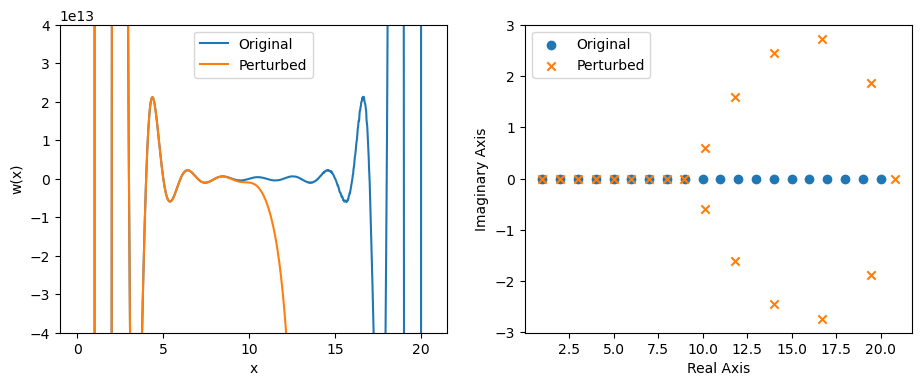

In [7]:
dom = np.linspace(0, 20.5, 1000)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(dom, np.polyval(w_coeffs.astype(float), dom), label="Original")
ax1.plot(dom, np.polyval(new_coeffs.astype(float), dom), label="Perturbed")
ax1.set_ylim(-4e13, 4e13)
ax1.set_xlabel("x"); ax1.set_ylabel("w(x)"); ax1.legend()
ax2.scatter(w_roots, np.zeros(20), label="Original")
ax2.scatter(new_roots.real, new_roots.imag, marker="x", label="Perturbed")
ax2.set_xlabel("Real Axis"); ax2.set_ylabel("Imaginary Axis"); ax2.legend()
plt.show()

A very small change in just a single coefficient drastically changes the nature of the polynomial and its roots. To quantify the difference, estimate the condition numbers (this example uses the $L^\infty$ norm to compute $\hat{\kappa}$ and $\kappa$).

In [8]:
# Sort the roots to ensure that they are in the same order.
w_roots = np.sort(w_roots)
new_roots = np.sort(new_roots)

# Estimate the absolute condition number in the infinity norm.
k = la.norm(new_roots - w_roots, np.inf) / la.norm(h, np.inf)
print(k)

# Estimate the relative condition number in the infinity norm.
k * la.norm(w_coeffs, np.inf) / la.norm(w_roots, np.inf)      # This is huge!!

28261476.233735397


1.95057314106855e+25

(The spec printed $28262391.3304$ and $1.95063629993970 \times 10^{25}$.)

There are some caveats to this example.

1. Computing the quotients in (10.1) and (10.2) for a fixed perturbation $\mathbf{h}$ only approximates the condition number. The true condition number is the limit of such quotients. We hope that when $\|\mathbf{h}\|$ is small, a random quotient is at least the same order of magnitude as the limit, but there is no way to be sure.
2. This example assumes that NumPy's root-finding algorithm, `np.roots()`, is stable, so that the difference between `w_roots` and `new_roots` is due to the difference in coefficients, and not to problems with `np.roots()`. The Stability section below returns to this issue.

Even with these caveats, it is apparent that root finding is a difficult problem to solve correctly. Always check your math carefully when dealing with polynomial roots.

## Problem 2: Perturbing the Wilkinson polynomial

> **Problem 2.** Write a function that carries out the following experiment 100 times.
>
> 1. Randomly perturb the true coefficients of the Wilkinson polynomial by replacing each coefficient $c_i$ with $c_i * r_i$, where $r_i$ is drawn from a normal distribution centered at 1 with standard deviation $10^{-10}$ (use `np.random.normal()`).
> 2. Plot the perturbed roots as small points in the complex plane. That is, plot the real part of the coefficients on the $x$-axis and the imaginary part on the $y$-axis. Plot on the same figure in each experiment.
>    (Hint: use a pixel marker, `marker=','`, to avoid overcrowding the figure.)
> 3. Compute the absolute and relative condition numbers with the $L^\infty$ norm.
>
> Plot the roots of the unperturbed Wilkinson polynomial with the perturbed roots. Your final plot should resemble Figure 10.2. Finally, return the average computed absolute and relative condition numbers.
>
> *[In Figure 10.2 the perturbed roots form a ring of clusters from about real part 5 to 22, reaching about $\pm 5$ on the imaginary axis, around the original roots $1, \ldots, 20$. It replicates Figure 12.1 on p. 93 of* Numerical Linear Algebra *by Lloyd N. Trefethen and David Bau III.]*

The perturbation in the condition number estimates is $\mathbf{h} = \tilde{\mathbf{c}} - \mathbf{c}$, the change in the coefficients. The original divided by $\|\mathbf{r}\|_\infty \approx 1$ (the vector of multipliers) instead, which made the "absolute condition number" just the change in the roots and threw off the relative one by the same factor; the denominator now uses the coefficient change.

In [9]:
def prob2():
    """Randomly perturb the coefficients of the Wilkinson polynomial by
    replacing each coefficient c_i with c_i*r_i, where r_i is drawn from a
    normal distribution centered at 1 with standard deviation 1e-10.
    Plot the roots of 100 such experiments in a single figure, along with the
    roots of the unperturbed polynomial w(x).

    Returns:
        (float) The average absolute condition number.
        (float) The average relative condition number.
    """
    w_roots = np.arange(1, 21)

    # Get the exact Wilkinson polynomial coefficients using SymPy.
    x, i = sy.symbols('x i')
    w = sy.poly_from_expr(sy.product(x-i, (i, 1, 20)))[0]
    w_coeffs = np.array(w.all_coeffs())
    abs_cond = []
    rel_cond = []
    # First, plot the Wilkinson roots.
    plt.ion()
    plt.scatter(np.real(w_roots), np.imag(w_roots), label="Original")
    for i in range(100):
        # Perturb each of the coefficients
        r = np.random.normal(1, 1e-10, len(w_coeffs))
        new_coeffs = w_coeffs * r
        new_roots = np.sort(np.roots(np.poly1d(new_coeffs)))
        # Plot each of the perturbed results
        if i == 0:
            plt.plot(np.real(new_roots), np.imag(new_roots), ',', c='k', label="Perturbed")
        else:
            plt.plot(np.real(new_roots), np.imag(new_roots), ',', c='k')
        # Store the absolute and relative condition numbers
        # Changed: divide by the perturbation h = new_coeffs - w_coeffs, not by r
        # (the multipliers, all about 1), as in (10.1).
        k = la.norm(new_roots - w_roots, np.inf) / la.norm(new_coeffs - w_coeffs, np.inf)
        abs_cond.append(k)
        rel_k = k * la.norm(w_coeffs, np.inf) / la.norm(w_roots, np.inf)
        rel_cond.append(rel_k)
    plt.xlabel("Real Axis")
    plt.ylabel("Imaginary Axis")
    plt.legend()
    plt.show()
    # Return the average of the condition numbers
    return np.mean(abs_cond), np.mean(rel_cond)

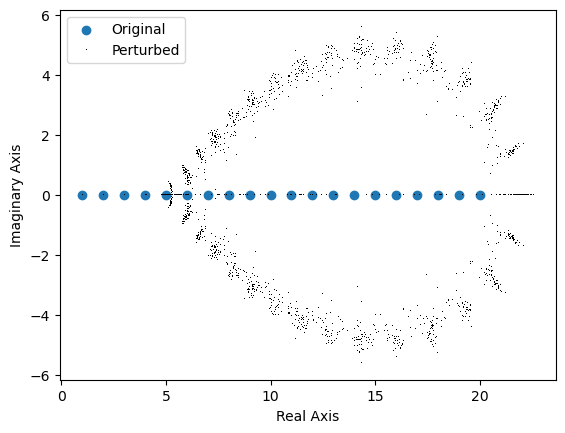

average absolute condition number: 3.6816e-09
average relative condition number: 2.5410e+09


In [10]:
np.random.seed(0)
abs_k, rel_k = prob2()
print(f"average absolute condition number: {float(abs_k):.4e}")
print(f"average relative condition number: {float(rel_k):.4e}")

The perturbations here change every coefficient by a relative amount of about $10^{-10}$, so $\|\mathbf{h}\|_\infty$ is around $10^{9}$ (the largest coefficient is about $1.4 \times 10^{19}$) and the absolute condition number comes out small. The relative condition number, which accounts for the scale of the coefficients and roots, is still enormous.

## Calculating Eigenvalues

Let $f : M_n(\mathbb{C}) \to \mathbb{C}^n$ be the function that maps an $n \times n$ matrix with complex entries to its $n$ eigenvalues. This problem is well-conditioned for symmetric matrices, but it can be extremely ill-conditioned for non-symmetric matrices. Let $A$ be an $n \times n$ matrix and let $\boldsymbol{\lambda}$ be the vector of the $n$ eigenvalues of $A$. If $\tilde{A} = A + H$ is a perturbation of $A$ and $\tilde{\boldsymbol{\lambda}}$ are its eigenvalues, then the condition numbers of $f$ can be estimated by

$$\hat{\kappa}(A) = \frac{\|\boldsymbol{\lambda} - \tilde{\boldsymbol{\lambda}}\|}{\|H\|}, \qquad \kappa(A) = \frac{\|A\|}{\|\boldsymbol{\lambda}\|}\hat{\kappa}(A). \tag{10.4}$$

## Problem 3: Eigenvalue condition number

> **Problem 3.** Write a function that accepts a matrix $A$ and estimates the condition number of the eigenvalue problem using (10.4). For the perturbation $H$, construct a matrix with complex entries where the real and imaginary parts are drawn from normal distributions centered at 0 with standard deviation $\sigma = 10^{-10}$.
>
> ```python
> reals = np.random.normal(0, 1e-10, A.shape)
> imags = np.random.normal(0, 1e-10, A.shape)
> H = reals + 1j*imags
> ```
>
> Use `scipy.linalg.eig()` or `scipy.linalg.eigvals()` to compute the eigenvalues of $A$ and $A + H$, and use the 2-norm for both the vector and matrix norms. Return the absolute and relative condition numbers.

In [11]:
def eig_cond(A):
    """Approximate the condition numbers of the eigenvalue problem at A.

    Parameters:
        A ((n,n) ndarray): A square matrix.

    Returns:
        (float) The absolute condition number of the eigenvalue problem at A.
        (float) The relative condition number of the eigenvalue problem at A.
    """
    # Create an n x n perturbation matrix H
    reals = np.random.normal(0, 1e-10, A.shape)
    imags = np.random.normal(0, 1e-10, A.shape)
    H = reals + 1j*imags
    # Calculate the eigenvalues of the original and the perturbed matrix
    A_eigs = la.eigvals(A)
    new_eigs = la.eigvals(A+H)
    # Solve for the condition numbers
    k = la.norm(A_eigs - new_eigs, 2) / la.norm(H, 2)
    rel_k = k * la.norm(A, 2) / la.norm(A_eigs, 2)
    return k, rel_k

For a symmetric matrix, no eigenvalue moves by more than $\|H\|_2$ (Bauer–Fike), so $\hat{\kappa}$ is at most about $\sqrt{n}$. A non-normal matrix such as a Jordan-like block with a large off-diagonal entry is far more sensitive.

In [12]:
np.random.seed(2)
for name, A in [("symmetric 4x4", (lambda B: B + B.T)(np.random.random((4, 4)))),
                ("[[1, 1000], [0, 1]]", np.array([[1., 1000.], [0., 1.]])),
                ("[[1, 100], [0.01, 1]]", np.array([[1., 100.], [.01, 1.]]))]:
    k, rel_k = eig_cond(A)
    print(f"{name:22} absolute {k:10.3e}   relative {rel_k:10.3e}")
    if name.startswith("symmetric"):
        assert k <= np.sqrt(len(A)) + 1e-3

symmetric 4x4          absolute  8.810e-01   relative  8.411e-01
[[1, 1000], [0, 1]]    absolute  2.513e+06   relative  1.777e+09
[[1, 100], [0.01, 1]]  absolute  7.820e+00   relative  3.910e+02


## Problem 4: Condition number heat map

> **Problem 4.** Write a function that accepts bounds $[x_{\min}, x_{\max}, y_{\min}, y_{\max}]$ and an integer `res`. Use your function from Problem 3 to compute the relative condition number of the eigenvalue problem for the $2 \times 2$ matrix
>
> $$\begin{bmatrix} 1 & x \\ y & 1 \end{bmatrix}$$
>
> at every point of an evenly spaced `res`$\times$`res` grid over the domain $[x_{\min}, x_{\max}] \times [y_{\min}, y_{\max}]$. Plot these estimated relative condition numbers using `plt.pcolormesh()` and the colormap `cmap='gray_r'`. With `res=200`, your plot should look similar to the following figure. *[The spec's figure, over $[-100, 100]^2$ with a color scale up to about $2.5 \times 10^{12}$, is a noisy gray field that is lightest near the origin and darkens toward the edges.]*

In [13]:
def prob4(domain=[-100, 100, -100, 100], res=50):
    """Create a grid [x_min, x_max] x [y_min, y_max] with the given resolution. For each
    entry (x,y) in the grid, find the relative condition number of the
    eigenvalue problem, using the matrix   [[1, x], [y, 1]]  as the input.
    Use plt.pcolormesh() to plot the condition number over the entire grid.

    Parameters:
        domain ([x_min, x_max, y_min, y_max]):
        res (int): number of points along each edge of the grid.
    """
    # Create the x and y domains depending on the bounds and the resolution
    x_dom = np.linspace(domain[0], domain[1], res)
    y_dom = np.linspace(domain[2], domain[3], res)
    X, Y = np.meshgrid(x_dom, y_dom)
    # Create a matrix that corresponds to each of the grid points
    C = []
    for x in x_dom:
        temp = []
        for y in y_dom:
            M = np.array([[1,x], [y,1]])
            k, r = eig_cond(M)
            temp.append(r)
        C.append(temp)

    # Plot the results in a pcolormesh
    plt.pcolormesh(X, Y, C, cmap='gray_r')
    plt.colorbar()
    plt.show()

At the spec's resolution, `res=200` (40,000 eigenvalue estimates, about a second):

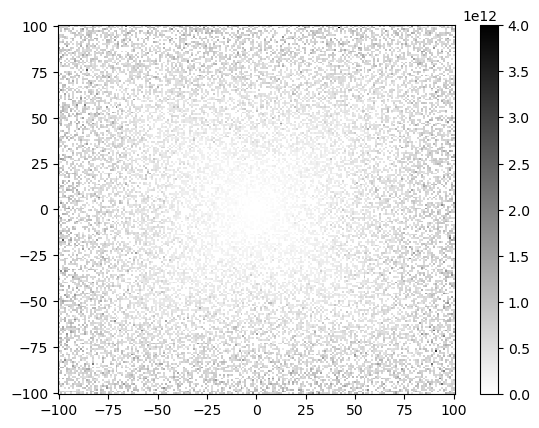

In [14]:
np.random.seed(3)
prob4(res=200)

Problem 4 shows that the conditioning of the eigenvalue problem depends heavily on the matrix, and that it is difficult to know a priori how bad the problem will be. Luckily, most real-world problems requiring eigenvalues are symmetric. In their book on Numerical Linear Algebra, L. Trefethen and D. Bau III summed up the issue of conditioning and eigenvalues when they stated, "if the answer is highly sensitive to perturbations, you have probably asked the wrong question."

## Stability

The stability of an algorithm is measured by the error in its output. Let $f : \mathbb{R}^m \to \mathbb{R}^n$ be a problem to be solved, and let $\tilde{f}$ be an actual algorithm for solving the problem. The *forward error* of $f$ at $\mathbf{x}$ is $\|f(\mathbf{x}) - \tilde{f}(\mathbf{x})\|$, and the *relative forward error* of $f$ at $\mathbf{x}$ is

$$\frac{\|f(\mathbf{x}) - \tilde{f}(\mathbf{x})\|}{\|f(\mathbf{x})\|}.$$

An algorithm is called *stable* if its relative forward error is small. (See the Additional Material for alternative, more rigorous definitions of algorithmic stability.)

As an example, consider again NumPy's root-finding algorithm on the Wilkinson polynomial. The exact roots of $w(x)$ are $1, 2, \ldots, 20$. Had we not known this, we could have computed the roots from the (unperturbed) coefficients using `np.roots()`.

In [15]:
# w_coeffs holds the coefficients and w_roots holds the true roots.
computed_roots = np.sort(np.roots(np.poly1d(w_coeffs)))
print(computed_roots[:6])               # The computed roots are close to integers.

# Compute the forward error.
forward_error = la.norm(w_roots - computed_roots)
print(forward_error)

# Compute the relative forward error.
forward_error / la.norm(w_roots)        # The error is nice and small.

[1.         2.         3.         3.99999997 5.00000088 5.99998696]
0.12057052418140426


np.float64(0.0022506097742347607)

(The spec printed the computed roots as `[ 1. 2. 3. 3.99999999 5.00000076 5.99998749]`, a forward error of $0.020612653126379665$, and a relative forward error of $0.00038476268486104599$. The exact digits depend on the NumPy/LAPACK build; the error here is a few times larger but still small.)

This analysis suggests that `np.roots()` is a stable algorithm, so large condition numbers of Problem 2 really are due to the poor conditioning of the problem, not the way in which the problem was solved.

> **Note.** Conditioning is a property of a *problem* to be solved, such as finding the roots of a polynomial or calculating eigenvalues. Stability is a property of an *algorithm* to solve a problem, such as `np.roots()` or `scipy.linalg.eig()`. If a problem is ill-conditioned, any algorithm used to solve that problem may result in suspicious solutions, even if that algorithm is stable.

### Least squares

The ordinary least squares (OLS) problem is to find the $\mathbf{x}$ that minimizes $\|A\mathbf{x} - \mathbf{b}\|_2$ for fixed $A$ and $\mathbf{b}$. An equivalent problem is solving $A^HA\mathbf{x} = A^H\mathbf{b}$, called the *normal equations*. A common application is polynomial approximation: given $m$ data points $\{(x_k, y_k)\}_{k=1}^m$, find the coefficients $\{c_i\}_{i=0}^n$ such that

$$y_k \approx c_nx_k^n + c_{n-1}x_k^{n-1} + \cdots + c_2x_k^2 + c_1x_k + c_0$$

for all $k$, with the smallest possible error. These $m$ linear equations yield the following linear system.

$$A\mathbf{x} = \begin{bmatrix} x_1^n & x_1^{n-1} & \cdots & x_1^2 & x_1 & 1 \\ x_2^n & x_2^{n-1} & \cdots & x_2^2 & x_2 & 1 \\ x_3^n & x_3^{n-1} & \cdots & x_3^2 & x_3 & 1 \\ \vdots & \vdots & & \vdots & \vdots & \vdots \\ x_m^n & x_m^{n-1} & \cdots & x_m^2 & x_m & 1 \end{bmatrix}\begin{bmatrix} c_n \\ c_{n-1} \\ \vdots \\ c_2 \\ c_1 \\ c_0 \end{bmatrix} = \begin{bmatrix} y_1 \\ y_2 \\ y_3 \\ \vdots \\ y_m \end{bmatrix} = \mathbf{b} \tag{10.5}$$

## Problem 5: Least squares stability

> **Problem 5.** Write a function that accepts an integer $n$. Solve for the coefficients of the polynomial of degree $n$ that best fits the data found in `stability_data.npy`. Use two approaches to get the least squares solution:
>
> 1. Use `la.inv()` to solve the normal equations: $\mathbf{x} = (A^TA)^{-1}A^T\mathbf{b}$. Although this approach seems intuitive, it is actually highly unstable and can return an answer with a very large forward error.
> 2. Use `la.qr()` with `mode='economic'` and `la.solve_triangular()` to solve the system $R\mathbf{x} = Q^T\mathbf{b}$, which is equivalent to solving the normal equations. This algorithm has the advantage of being stable.
>
> Load the data and set up the system (10.5) with the following code.
>
> ```python
> xk, yk = np.load("stability_data.npy").T
> A = np.vander(xk, n+1)
> ```
>
> Plot the resulting polynomials together with the raw data points. Return the forward error $\|A\mathbf{x} - \mathbf{b}\|_2$ of both approximations.
>
> (Hint: The function `np.polyval()` will be helpful for plotting the resulting polynomials.)
>
> Test your function using various values of $n$, taking special note of what happens for values of $n$ near 14 (pictured below). *[The spec's figure shows the data on $[0, 1]$: the QR solver's polynomial follows the data, while the normal equations' polynomial shoots up to about 25 past $x = 0.6$.]*

In [16]:
def prob5(n):
    """Approximate the data from "stability_data.npy" on the interval [0,1]
    with a least squares polynomial of degree n. Solve the least squares
    problem using the normal equation and the QR decomposition, then compare
    the two solutions by plotting them together with the data. Return
    the mean squared error of both solutions, ||Ax-b||_2.

    Parameters:
        n (int): The degree of the polynomial to be used in the approximation.

    Returns:
        (float): The forward error using the normal equations.
        (float): The forward error using the QR decomposition.
    """
    # Load the data and create the vandermonde matrix
    xk, yk = np.load("stability_data.npy").T
    A = np.vander(xk, n+1)
    # Solve for the least square solution using the inverse of A.T@A
    c1 = la.inv(A.T @ A) @ A.T @ yk
    Q, R = la.qr(A, mode='economic')
    # Solve for the least square solution using QR decomposition
    c2 = la.solve_triangular(R, Q.T@yk)
    domain = np.linspace(0, 1, 500)
    # Plot the two graphs along with the original data
    plt.plot(xk, yk, 'k*', ms=2, label="Data points")
    plt.plot(domain, np.polyval(c1, domain), label="Normal Equations")
    plt.plot(domain, np.polyval(c2, domain), label="QR Solver")
    plt.legend()
    plt.show()
    # Solve for the forward errors
    fe1 = la.norm(A@c1 - yk, 2)
    fe2 = la.norm(A@c2 - yk, 2)
    return fe1, fe2

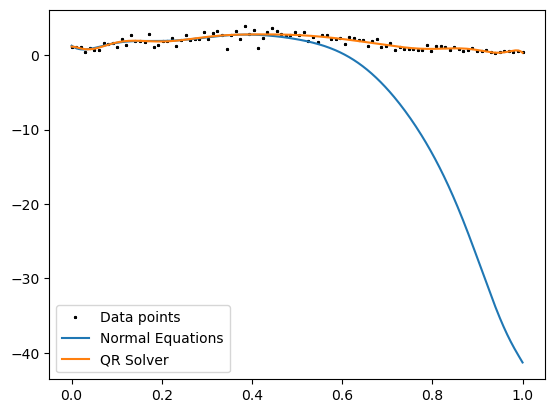

(137.90583762140344, 4.568370945834199)

In [17]:
prob5(14)

The forward errors for several degrees (plots suppressed), with the residual of SciPy's SVD-based `la.lstsq()` for comparison. The QR solution matches `la.lstsq()`, while the normal equations break down as $n$ grows and $\kappa(A^TA) = \kappa(A)^2$ explodes.

In [18]:
from unittest import mock

xk, yk = np.load("stability_data.npy").T
print(f"{'n':>3}{'normal eqns':>14}{'QR':>12}{'la.lstsq':>12}{'cond(A)':>12}")
with mock.patch.object(plt, "show", lambda: plt.close("all")):      # Skip the plots.
    for n in [2, 4, 6, 8, 10, 12, 13, 14, 15, 16]:
        fe1, fe2 = prob5(n)
        A = np.vander(xk, n+1)
        ref = la.norm(A @ la.lstsq(A, yk)[0] - yk)
        assert np.isclose(fe2, ref, rtol=1e-6)
        print(f"{n:3d}{fe1:14.4f}{fe2:12.4f}{ref:12.4f}{np.linalg.cond(A):12.2e}")

  n   normal eqns          QR    la.lstsq     cond(A)
  2        5.5340      5.5340      5.5340    2.25e+01
  4        4.8702      4.8702      4.8702    6.65e+02
  6        4.7713      4.7713      4.7713    2.07e+04
  8        4.6999      4.6999      4.6999    6.56e+05
 10        4.6444      4.6443      4.6443    2.12e+07
 12       43.6568      4.5934      4.5934    6.90e+08
 13       77.8831      4.5934      4.5934    3.95e+09
 14      137.9058      4.5684      4.5684    2.27e+10
 15      146.6010      4.5276      4.5276    1.31e+11
 16      186.6647      4.5204      4.5204    7.56e+11


## Catastrophic Cancellation

When a computer takes the difference of two very similar numbers, the result is often stored with a small number of significant digits and the tiniest bit of information is lost. These small errors can propagate into large errors later down the line. This phenomenon is called *catastrophic cancellation*, and is a common cause for numerical instability.

Catastrophic cancellation is a potential problem whenever floats or large integers that are very close to one another are subtracted. It can be avoided by rewriting the program to not use subtraction, or by increasing the number of significant digits that the computer tracks. For example, $\sqrt{a} - \sqrt{b}$ can be computed directly with subtraction, or by performing the equivalent division

$$\sqrt{a} - \sqrt{b} = (\sqrt{a} - \sqrt{b})\frac{\sqrt{a} + \sqrt{b}}{\sqrt{a} + \sqrt{b}} = \frac{a - b}{\sqrt{a} + \sqrt{b}}.$$

In [19]:
from math import sqrt           # np.sqrt() fails for very large numbers.
a = 10**20 + 1
b = 10**20
print(sqrt(a) - sqrt(b))                # Do the subtraction directly: a != b, so information has been lost.
print((a - b) / (sqrt(a) + sqrt(b)))    # Use the alternative formulation. Much better!

0.0
5e-11


In this example, $a$ and $b$ are distinct enough that the computer can still tell that $a - b = 1$, but $\sqrt{a}$ and $\sqrt{b}$ are so close to each other that $\sqrt{a} - \sqrt{b}$ is computed as 0.

## Problem 6: An unstable recurrence

> **Problem 6.** Let $I(n) = \int_0^1 x^ne^{x-1}\,dx$. It can be shown that for a positive integer $n$,
>
> $$I(n) = (-1)^n\,!n + (-1)^{n+1}\frac{n!}{e}, \tag{10.6}$$
>
> where $!n = n!\sum_{k=0}^n \frac{(-1)^k}{k!}$ is the subfactorial of $n$. Write a function to do the following.
>
> 1. Use SymPy's `sy.integrate()` to evaluate the integral form of $I(n)$ for $n = 5, 10, \ldots, 50$. Convert the symbolic results of each integration to a float. Since this is done symbolically, these values can be accepted as the true values of $I(n)$.
>    (Hint: be careful that the values of $n$ in the integrand are actual integers, not floats.)
> 2. Use (10.6) to compute $I(n)$ for the same values of $n$. Use `sy.subfactorial()` to compute $!n$ and `sy.factorial()` to compute $n!$.
>    (Hint: be careful to only pass actual integers to these functions.)
> 3. Plot the relative forward error of the results computed in step 2 at each of the given values of $n$. Use a log scale on the $y$-axis. Is (10.6) a stable way to compute $I(n)$? Why?

In [20]:
def prob6():
    """For n = 5, 10, ..., 50, compute the integral I(n) using SymPy (the
    true values) and the subfactorial formula (may or may not be correct).
    Plot the relative forward error of the subfactorial formula for each
    value of n. Use a log scale for the y-axis.
    """
    # Create a list containing the values of n
    N = [i * 5 for i in range(1,11)]
    errors = []
    for n in N:
        # Solve for the integral using sy.integrate()
        x = sy.symbols('x')
        f = x**n * sy.exp(x - 1)
        r1 = float(sy.integrate(f, (x, 0, 1)))
        # Solve for the integral using the equation 10.6
        r2 = float((-1)**n * sy.subfactorial(n)) + (-1)**(n+1) * sy.factorial(n)/np.exp(1)
        ref = abs(r1-r2)/abs(r1)
        errors.append(ref)
    # Plot the resulting errors in a semilogy graph
    plt.semilogy(N, errors)
    plt.xlabel("n")
    plt.ylabel("Reletive forward error")

    '''
    10.6 is a stable way to compute I(n) since when calculated this way, the 
    relative forward error stays at around 1 even for large n.
    '''

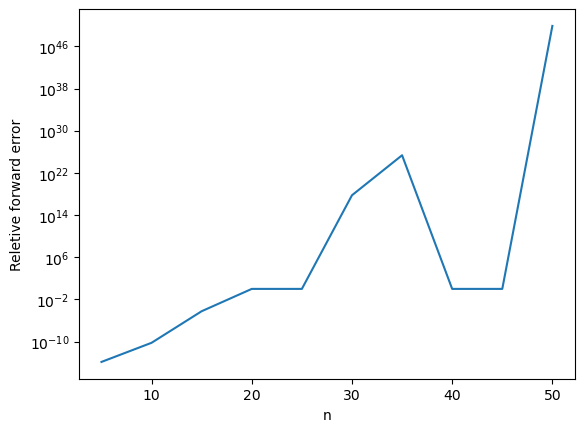

In [21]:
prob6()
plt.show()

Points where the formula happens to round to exactly 0 show a relative error of exactly 1; the rest grow without bound. The true values $I(n)$ shrink toward 0 (roughly like $1/n$) while $n!/e$ grows factorially, so the formula loses all its accuracy to cancellation.

## Additional Material

### Other notions of stability

The definition of stability can be made more rigorous in the following way. Let $f$ be a problem to solve and $\tilde{f}$ an algorithm to solve it. If for every $\mathbf{x}$ in the domain there exists a $\tilde{\mathbf{x}}$ such that

$$\frac{\|\tilde{\mathbf{x}} - \mathbf{x}\|}{\|\mathbf{x}\|} \qquad \text{and} \qquad \frac{\|\tilde{f}(\mathbf{x}) - f(\tilde{\mathbf{x}})\|}{\|f(\tilde{\mathbf{x}})\|}$$

are small (close to $\epsilon_{\text{machine}} \approx 10^{-16}$), then $\tilde{f}$ is called *stable*. In other words, "a stable algorithm gives nearly the right answer to nearly the right question" (Trefethen, Bao, 104). Note carefully that the quantity on the right is slightly different from the plain forward error introduced earlier.

Stability is desirable, but plain stability isn't the best possible condition. If for every input $\mathbf{x}$ there exists a $\tilde{\mathbf{x}}$ such that $\|\tilde{\mathbf{x}} - \mathbf{x}\|/\|\mathbf{x}\|$ is small and $\tilde{f}(\mathbf{x}) = f(\tilde{\mathbf{x}})$ exactly, then $\tilde{f}$ is called *backward stable*: it gives exactly the right answer to nearly the right question. Backward stable algorithms are generally more trustworthy than stable algorithms, but they are also less common.

### Stability of linear system solvers

The algorithms presented so far in the manual have different levels of stability. The LU decomposition (with pivoting) is usually very good, but there are some pathological examples of matrices that can cause it to break down. Even so, `scipy.linalg.solve()` uses the LU decomposition. The QR decomposition (also with pivoting) is generally considered to be a better option than the LU decomposition and is more stable. However, solving a linear system using the SVD is even more stable than using the QR decomposition. For this reason, `scipy.linalg.lstsq()` uses the SVD.